# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [1]:
import pandas as pd
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "notebook"

df = pd.read_csv(
    "/kaggle/input/datasets/bhanuprasadspirit/world-population/world_population.csv"
)

df = df.rename(columns={
    "Country/Territory": "Country",
    "Area (km²)": "Area",
    "Density (per km²)": "Density",
    "World Population Percentage": "World share (%)",
})

year_cols = [column for column in df.columns if column.endswith(" Population")]

df_long = df.melt(
    id_vars=["CCA3", "Country", "Continent"],
    value_vars=year_cols,
    var_name="Year",
    value_name="Population",
)
df_long["Year"] = df_long["Year"].str[:4].astype(int)

BLUE = "#0072B2"
GRAY = "#B8BDC4"

print(df.shape, df_long.shape)

(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

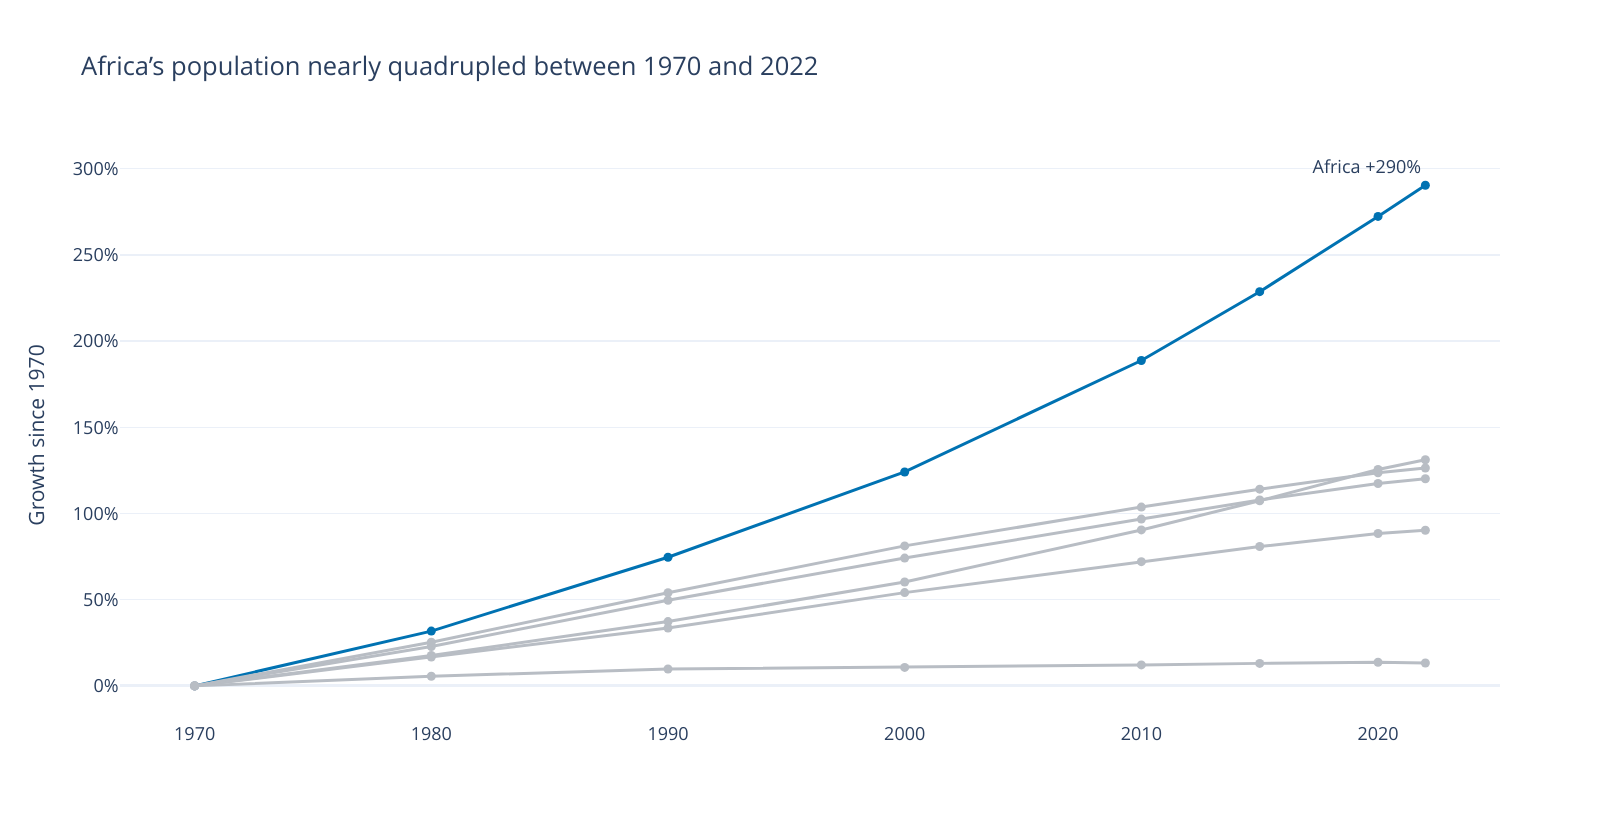

In [2]:
# Q1
# YOUR CODE HERE
growth = (
    df_long.groupby(["Continent", "Year"], as_index=False)["Population"]
    .sum()
    .sort_values(["Continent", "Year"])
)
baseline = growth.groupby("Continent")["Population"].transform("first")
growth["Growth (%)"] = 100 * (growth["Population"] / baseline - 1)

colors = dict.fromkeys(growth["Continent"].unique(), GRAY)
colors["Africa"] = BLUE

fig = px.line(
    growth, x="Year", y="Growth (%)", color="Continent",
    color_discrete_map=colors, markers=True, template="plotly_white",
    title="Africa’s population nearly quadrupled between 1970 and 2022",
)
fig.update_layout(showlegend=False)
fig.update_xaxes(title=None, showgrid=False)
fig.update_yaxes(title="Growth since 1970", ticksuffix="%")
fig.add_annotation(
    x=2022, y=290.41, text="Africa +290%",
    showarrow=False, xanchor="right", yshift=13,
)
fig.show()

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

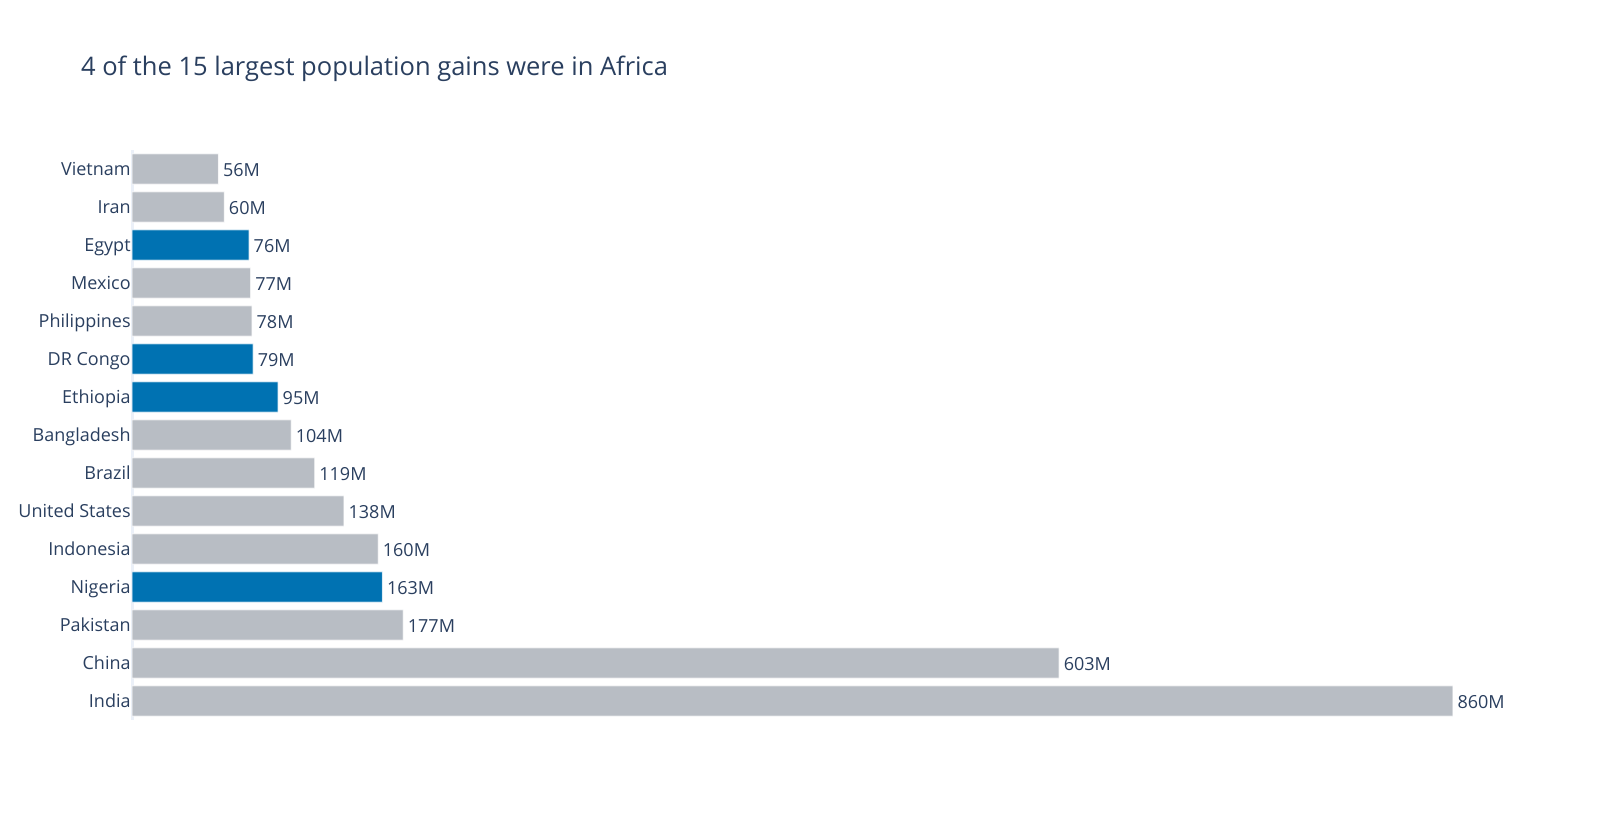

In [3]:
# Q2
# YOUR CODE HERE
gains = df.assign(
    Added=df["2022 Population"] - df["1970 Population"]
).nlargest(15, "Added").copy()

gains["Added (millions)"] = gains["Added"] / 1_000_000
gains["Group"] = gains["Continent"].where(
    gains["Continent"].eq("Africa"), "Other continents"
)
gains["Label"] = gains["Added (millions)"].map(lambda value: f"{value:.0f}M")
africa_count = gains["Continent"].eq("Africa").sum()

fig = px.bar(
    gains, x="Added (millions)", y="Country", orientation="h",
    color="Group", color_discrete_map={"Africa": BLUE, "Other continents": GRAY},
    text="Label", category_orders={"Country": gains["Country"].tolist()},
    template="plotly_white",
    title=f"{africa_count} of the 15 largest population gains were in Africa",
)
fig.update_traces(textposition="outside", cliponaxis=False)
fig.update_yaxes(title=None, autorange="reversed")
fig.update_xaxes(title=None, showgrid=False, showticklabels=False)
fig.update_layout(showlegend=False, margin=dict(r=65))
fig.show()

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

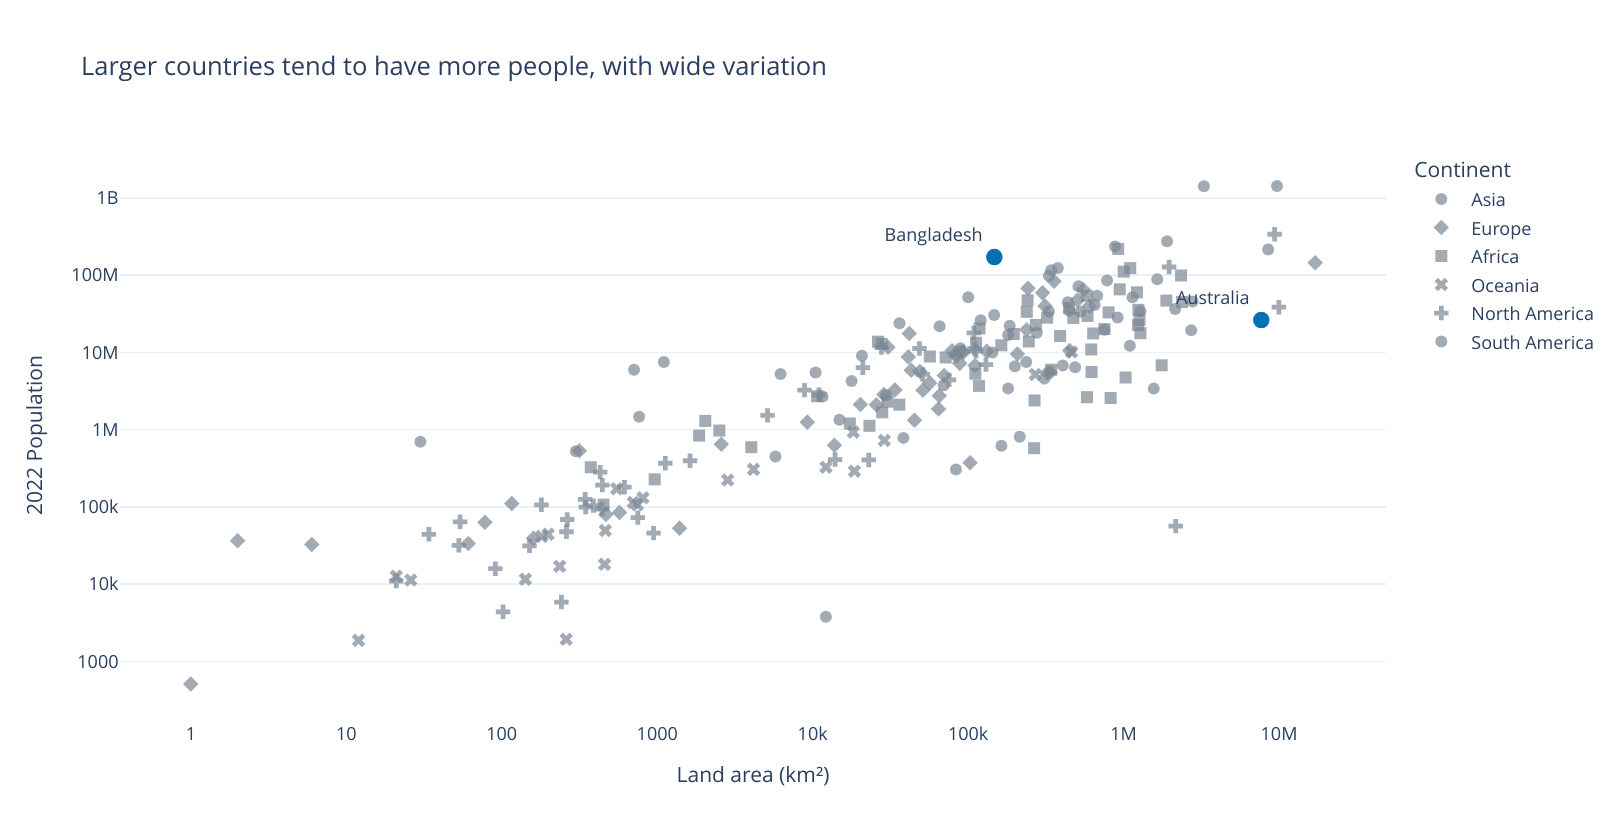

In [4]:
# Q3
# YOUR CODE HERE
examples = ["Bangladesh", "Australia"]

fig = px.scatter(
    df, x="Area", y="2022 Population",
    symbol="Continent", hover_name="Country",
    log_x=True, log_y=True, template="plotly_white",
    labels={"Area": "Land area (km²)"},
    title="Larger countries tend to have more people, with wide variation",
)
fig.update_traces(marker=dict(color="#7B8794", size=8, opacity=0.7))
fig.update_xaxes(showgrid=False)

for country in examples:
    row = df.loc[df["Country"].eq(country)].iloc[0]
    fig.add_scatter(
        x=[row["Area"]], y=[row["2022 Population"]],
        mode="markers+text", text=[country], textposition="top left",
        marker=dict(color=BLUE, size=11),
        name=country, showlegend=False,
    )

fig.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

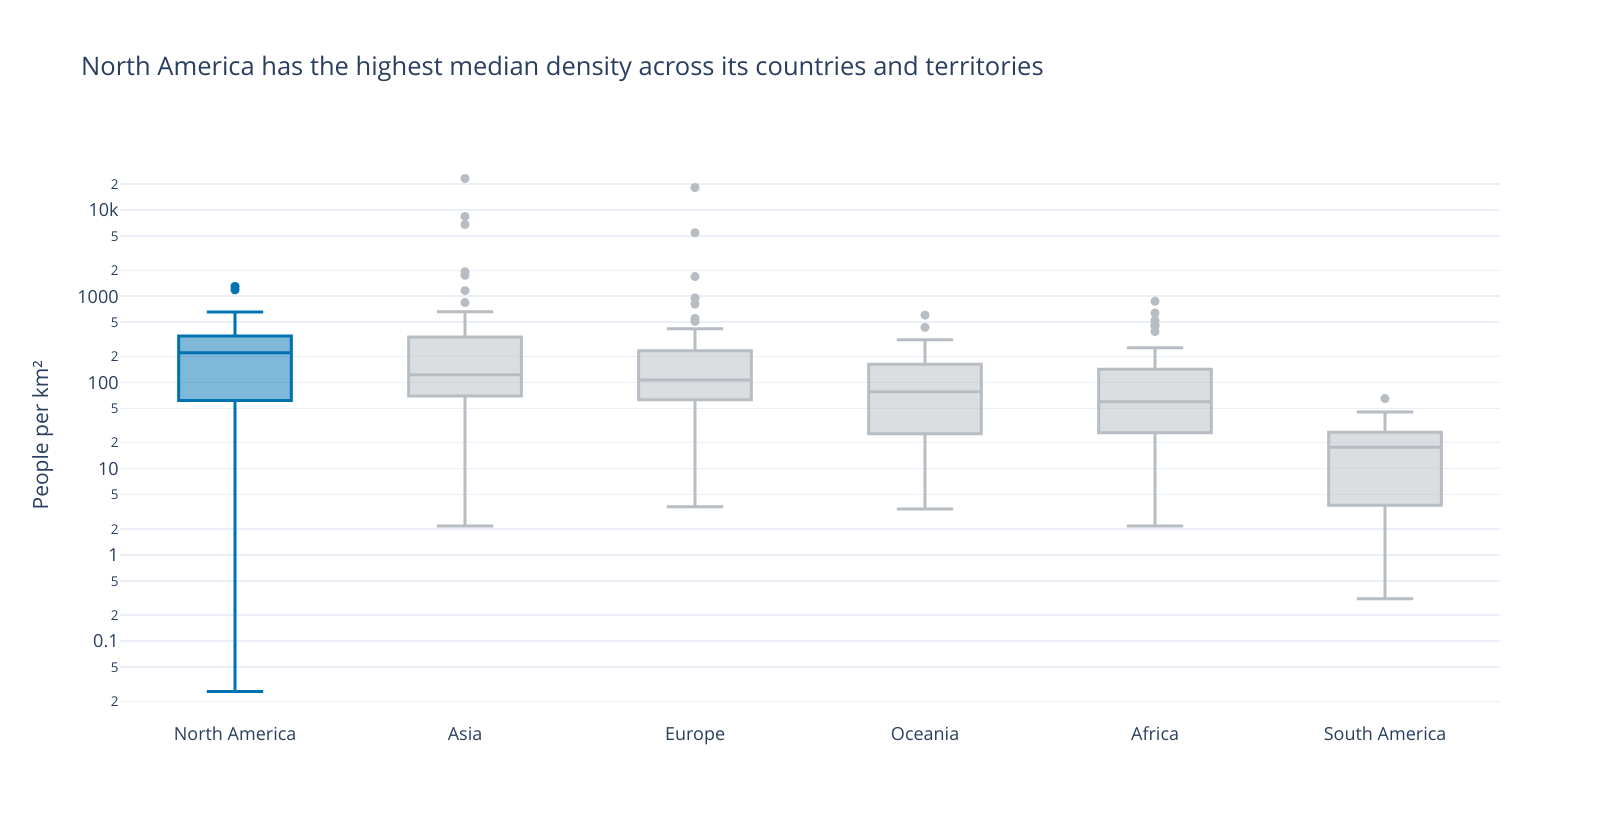

In [5]:
# Q4
# YOUR CODE HERE
density_order = (
    df.groupby("Continent")["Density"].median()
    .sort_values(ascending=False)
    .index.tolist()
)

fig = px.box(
    df, x="Continent", y="Density", color="Continent",
    log_y=True, points="outliers", hover_name="Country",
    category_orders={"Continent": density_order},
    color_discrete_map={
        continent: BLUE if continent == density_order[0] else GRAY
        for continent in density_order
    },
    template="plotly_white",
    labels={"Density": "People per km²"},
    title="North America has the highest median density across its countries and territories",
)
fig.update_layout(showlegend=False)
fig.update_xaxes(title=None)
fig.show()

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

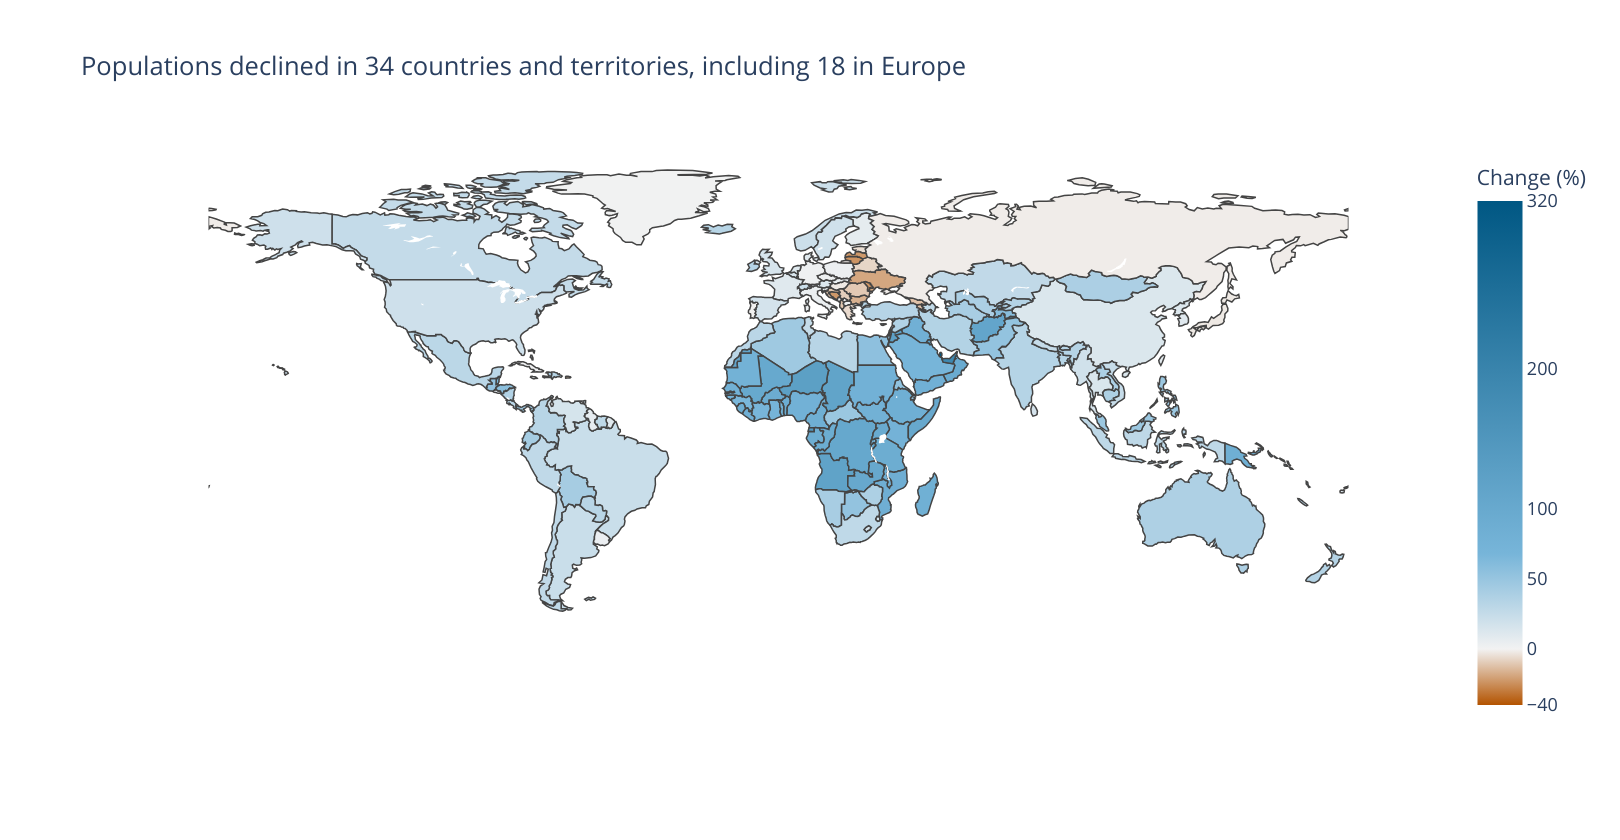

In [6]:
# Q5
# YOUR CODE HERE
change = df.assign(
    Change=100 * (df["2022 Population"] / df["2000 Population"] - 1)
)
declines = change["Change"].lt(0).sum()

# Zero is one ninth of the way from −40% to +320%.
fig = px.choropleth(
    change, locations="CCA3", locationmode="ISO-3",
    color="Change", hover_name="Country",
    hover_data={"CCA3": False, "Change": ":.1f"},
    range_color=(-40, 320),
    color_continuous_scale=[
        (0, "#B35300"),
        (1 / 9, "#F2F2F2"),
        (0.30, "#77B5D9"),
        (1, "#005783"),
    ],
    labels={"Change": "Change (%)"},
    template="plotly_white",
    title=f"Populations declined in {declines} countries and territories, including 18 in Europe",
)
fig.update_coloraxes(
    colorbar=dict(tickvals=[-40, 0, 50, 100, 200, 320], ticksuffix="%")
)
fig.update_geos(showframe=False, showcoastlines=False)
fig.show()

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

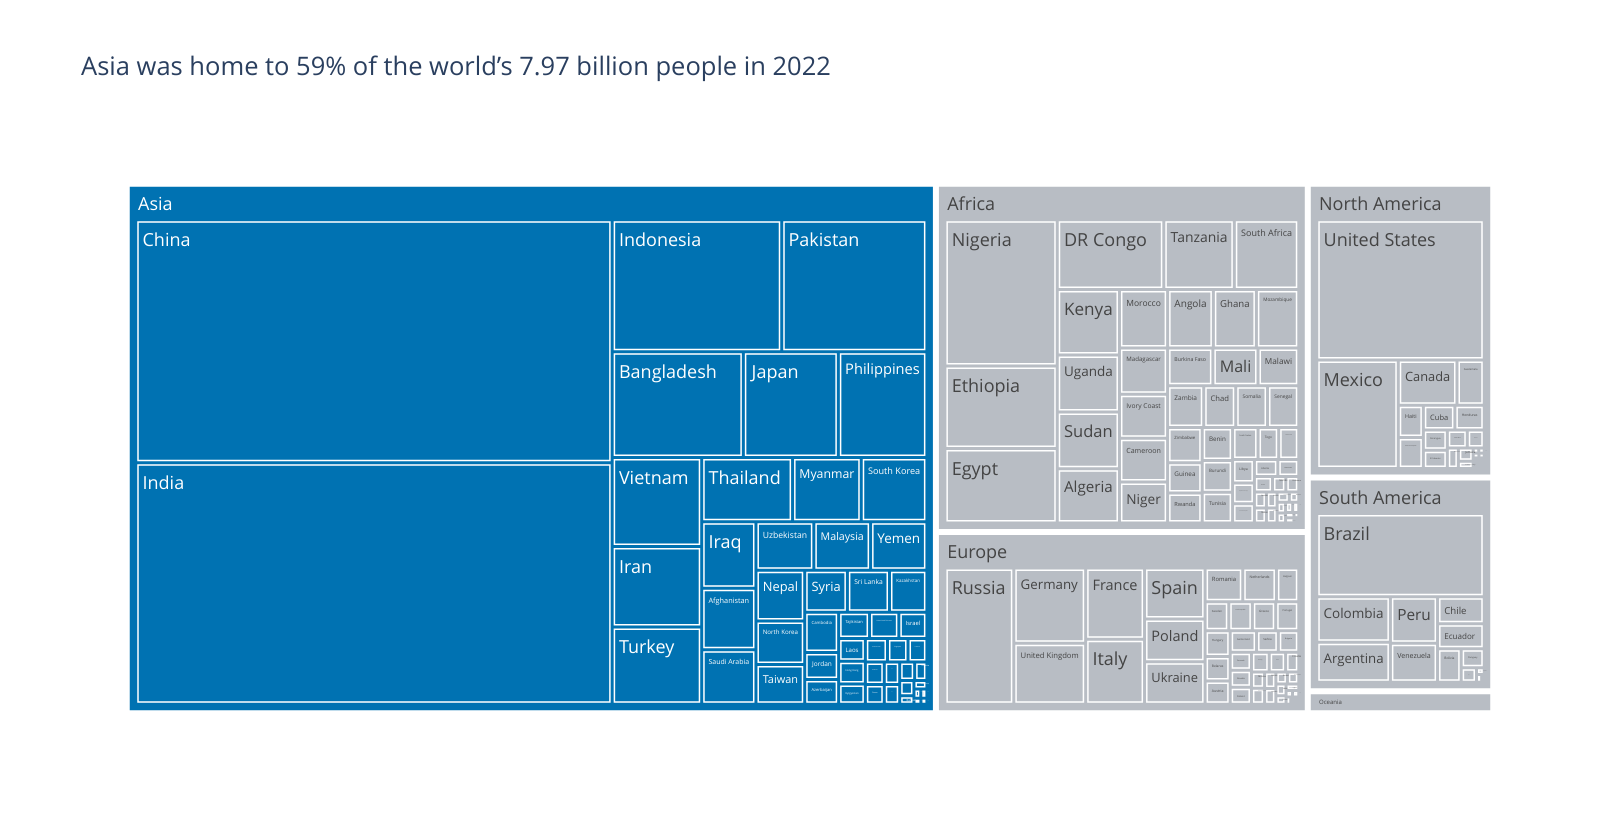

In [7]:
# Q6
# YOUR CODE HERE
continent_colors = dict.fromkeys(df["Continent"].unique(), GRAY)
continent_colors["Asia"] = BLUE

fig = px.treemap(
    df, path=["Continent", "Country"], values="2022 Population",
    color="Continent", color_discrete_map=continent_colors,
    template="plotly_white",
    title="Asia was home to 59% of the world’s 7.97 billion people in 2022",
)
fig.update_traces(
    textinfo="label",
    hovertemplate="%{label}<br>Population: %{value:,}<extra></extra>",
)
fig.show()

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

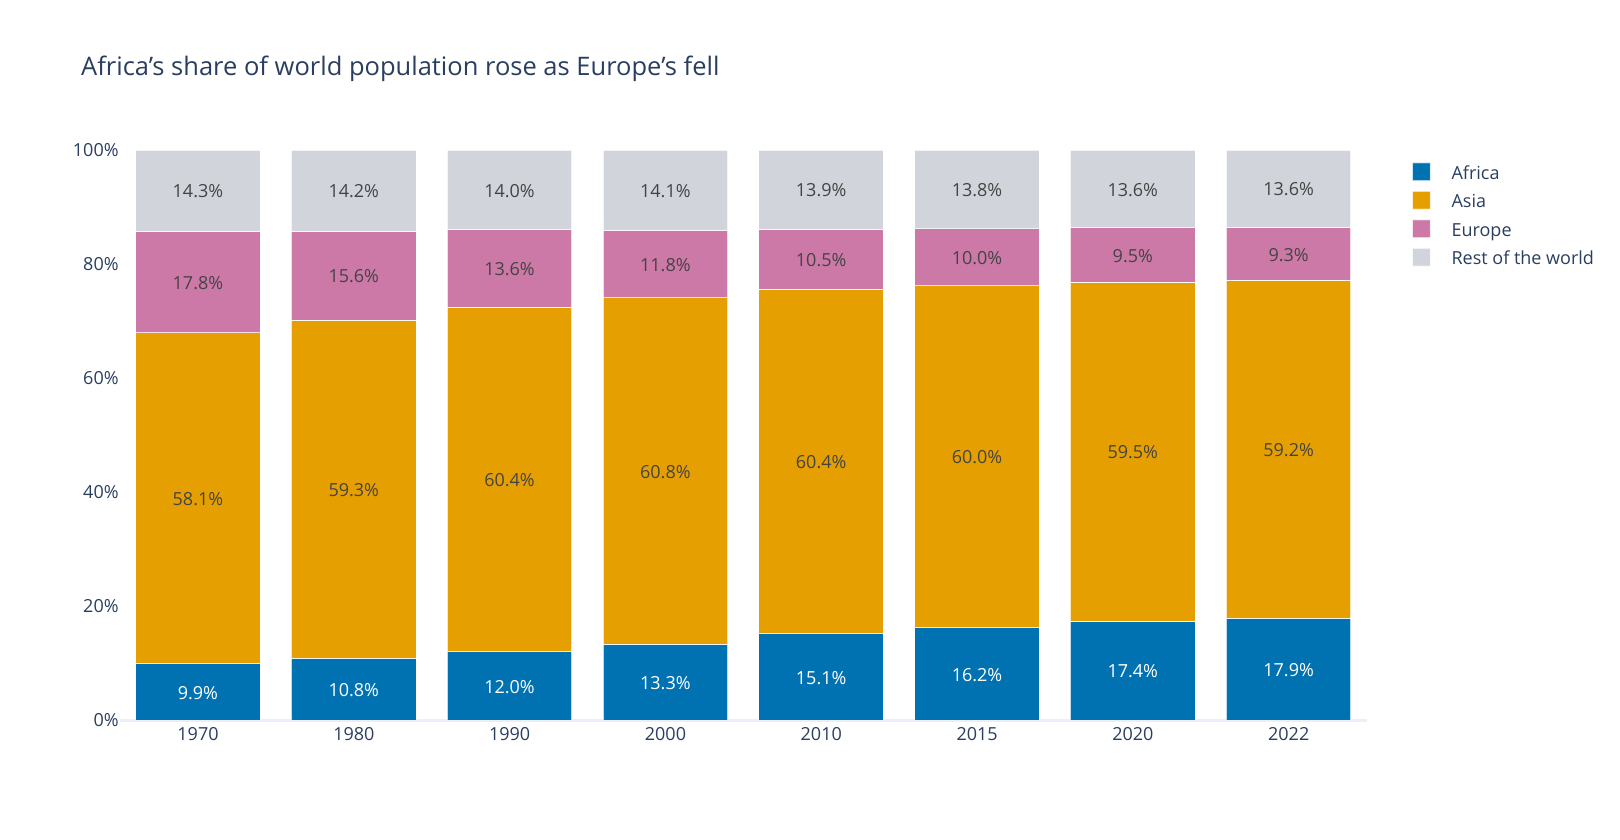

In [8]:
# Q7
# YOUR CODE HERE
groups = ["Africa", "Asia", "Europe", "Rest of the world"]

share = df_long.assign(
    Group=df_long["Continent"].where(
        df_long["Continent"].isin(groups), "Rest of the world"
    )
)
share = (
    share.groupby(["Year", "Group"], as_index=False)["Population"]
    .sum()
    .sort_values("Year")
)
world_total = share.groupby("Year")["Population"].transform("sum")
share["Share (%)"] = 100 * share["Population"] / world_total
share["Label"] = share["Share (%)"].map(lambda value: f"{value:.1f}%")
share["Year"] = share["Year"].astype(str)

fig = px.bar(
    share, x="Year", y="Share (%)", color="Group", text="Label",
    barmode="stack", category_orders={"Group": groups},
    color_discrete_map={
        "Africa": "#0072B2",
        "Asia": "#E69F00",
        "Europe": "#CC79A7",
        "Rest of the world": "#D1D5DB",
    },
    template="plotly_white",
    title="Africa’s share of world population rose as Europe’s fell",
)
fig.update_traces(textposition="inside", insidetextanchor="middle")
fig.update_xaxes(title=None, type="category")
fig.update_yaxes(title=None, range=[0, 100], ticksuffix="%", showgrid=False)
fig.update_layout(legend_title_text="")
fig.show()